# Latent Space Analysis and Variational Autoencoders

This notebook is the companion to **Stage 1 (Autoencoders and CNN-Based
Autoencoders)**. It does **not** repeat the dense/convolutional
autoencoders already covered there; instead it goes one level deeper:

```text
1. How does reconstruction error scale with the latent dimension d?
   (autoencoder vs POD)
2. What does the latent space actually look like?
   (2D projection, trajectory over time, interpolation)
3. Variational Autoencoders (VAE): a regularized, probabilistic latent space
   that can also be sampled from to generate new, synthetic fields.
```

The dataset is the same 2D DNS simulation of viscous flow past two collinear
plates used in Stage 1. This notebook is self-contained: it reloads the data
and rebuilds the autoencoder building blocks it needs, so it can be run
independently of Stage 1.


# Stage 2 — Structuring the latent space: latent size, trajectories and a variational autoencoder

**Portfolio project: compress, structure and evolve one flow dataset — autoencoders, a VAE and a Koopman autoencoder.**

This notebook asks three questions about the latent space of Stage 1's dense autoencoder on the same two-plate wake data (1,000 snapshots of u and v on a 128 × 64 grid, mean flow removed, the same 800 / 200 split). How does the reconstruction error fall with the latent size d (2, 5, 10, 20, 50) compared with POD of the same rank? What do the latent coordinates look like as a trajectory in time, next to the POD coefficients, and what happens between two latent codes? And what changes when the encoder outputs a distribution (a variational autoencoder, VAE, with a Kullback–Leibler pull towards a standard normal prior), so that new fields can be decoded from random draws? I solve the five experiments (full-budget sweep, 3-D latent trajectory, β sweep, convolutional VAE, latent arithmetic), repeat every training with the seeds 0, 1 and 2, and record a training animation of the VAE.

**How it connects.** It reloads the dataset and re-implements Stage 1's dense builders, split and POD baseline. Stage 3 asks how a latent state evolves in time, and Stage 4 compares POD, the autoencoder and the VAE across latent sizes with POD fitted on the training snapshots only.

**About the outputs.** The outputs below come from my single run (Apple M3 Max, 2026-10-13; dense networks on the Apple GPU, the convolutional VAE on the CPU, chosen by timing one training step of each). Afterwards I changed only text for this repository: this cell and the paths cell, the path lines (dataset from `../release_assets/`, models to `../models/02_latent_space_and_vae/`, tables to `../results/02_latent_space_and_vae/`, animation to `../animations/02_*`), comments, labels and printed text. Two quirks are kept as written: Section 7 says it keeps the d = 20 autoencoder but keeps the d = 10 model under a d = 20 name, and the POD error is computed on all snapshots while the networks are scored on the validation snapshots.

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
DATA_FILE = Path("../release_assets/G1Re100_coarse.npz")      # release file (README); downloaded by the data cell if missing
for p in (Path("../models/02_latent_space_and_vae/checkpoints"), Path("../results/02_latent_space_and_vae/exercises"), Path("../animations")):
    p.mkdir(parents=True, exist_ok=True)
print("dataset present:", DATA_FILE.exists())

In [1]:
# Device report.
# Device per network from the step timing of 2026-10-13 (median of 30 training steps inside model.fit, batch 32;
# ../results/04_rollout_and_baselines/device_timing_*.csv), CPU vs Apple GPU in ms: dense AE 19.5 vs 9.6, dense VAE 19.7 vs 11.3,
# Koopman AE 10.3 vs 9.9 -> GPU; conv AE 37.7 vs 624, two-block conv AE 63.5 vs 729, conv VAE 37.8 vs 625,
# non-linear Koopman AE 10.4 vs 12.1 -> CPU (the convolutional ones train under tf.device('/CPU:0')).
import tensorflow as tf, platform
print("TensorFlow", tf.__version__, "| Python", platform.python_version())
print("Physical devices:", tf.config.list_physical_devices())
print("GPU (Metal) visible:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow 2.18.1 | Python 3.12.14
Physical devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU (Metal) visible: True


# 1. Environment

Required packages:

```bash
pip install numpy tensorflow matplotlib scikit-learn gdown pydot graphviz
```


In [2]:
# =========================================================
# Import libraries
# =========================================================

from pathlib import Path
import json

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, activations, optimizers, callbacks
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

np.random.seed(0)
tf.random.set_seed(0)

print("TensorFlow version:", tf.__version__)
print("Current working directory:", Path.cwd())


TensorFlow version: 2.18.1
Current working directory: <repository>/notebooks


# 2. Optional: Google Colab Setup


In [3]:
# =========================================================
# Check whether we are running in Google Colab
# =========================================================
import os
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Google Colab:", IN_COLAB)

if IN_COLAB:
    from google.colab import drive
    # [original] drive.mount("/content/drive")
    pass  # Google Drive is not mounted: the dataset is in the local data folder (see the data_dir cell)
    print("Google Drive mounted.")
    os.chdir("/content/drive/<Drive folder>/latent-dynamics-ae-vae-koopman/notebooks")
    print(os.getcwd())
else:
    print("This is not Google Colab.")
    print("Current working directory:")
    print(Path.cwd())


Running in Google Colab: False
This is not Google Colab.
Current working directory:
<repository>/notebooks


# 3. Define Data Paths and Load the Dataset

Same dataset and paths as in Stage 1. If you already downloaded the file for
Stage 1, this cell reuses the local copy; otherwise it downloads it again.


In [4]:
# =========================================================
# Define data paths (must match Stage 1)
# =========================================================

if IN_COLAB:
    data_dir = Path("/content/drive/<Drive folder>/latent-dynamics-ae-vae-koopman/release_assets")
else:
    data_dir = Path("../release_assets")  # path line: the dataset from the release (README), or downloaded here from the URL below

data_dir.mkdir(parents=True, exist_ok=True)

data_file = data_dir / "G1Re100_coarse.npz"

url = "https://drive.google.com/uc?id=1b_pJl1XBfzlb93IcB4USht1voHBW6-IE"

DOWNLOAD_DATA = False

print("Dataset file:")
print(data_file)
print("File exists:", data_file.exists())

if DOWNLOAD_DATA or not data_file.exists():
    import gdown
    print("Downloading dataset from Google Drive...")
    gdown.download(url, str(data_file), quiet=False)
else:
    print("Using existing local dataset.")


Dataset file:
../release_assets/G1Re100_coarse.npz
File exists: True
Using existing local dataset.


In [5]:
# =========================================================
# Load the dataset and remove the mean flow
# =========================================================

data = np.load(data_file)

v = data["UV"]
xx = data["x"]
yy = data["y"]

v_mean = v.mean(axis=0)
v = v - v_mean

n_t, n_x, n_y, n_v = v.shape
input_shape = (n_x, n_y, n_v)
n_state_variables = n_x * n_y * n_v

print("Velocity field shape:", v.shape)
print("Full state dimension:", n_state_variables)


Velocity field shape: (1000, 128, 64, 2)
Full state dimension: 16384


# 4. Train/Validation Split

Same 80/20 split as Stage 1 (same `random_state`, so the split is identical).


In [6]:
# =========================================================
# Train/validation split
# =========================================================

v_trn, v_val = train_test_split(
    v,
    test_size=0.2,
    random_state=24,
    shuffle=True
)

print("Training snapshots:  ", v_trn.shape[0])
print("Validation snapshots:", v_val.shape[0])


Training snapshots:   800
Validation snapshots: 200


# 5. Recap: Dense Autoencoder Builders

Same building blocks as Stage 1, Section 7, reproduced here so this notebook
does not depend on having Stage 1 open at the same time.


In [7]:
# =========================================================
# Dense encoder / decoder building blocks (same as Stage 1)
# =========================================================


def create_dense_encoder(
    input_shape,
    latent_dim,
    hidden_units=512,
    activation="relu",
    dropout_rate=0.1
):
    """
    Create a dense (fully connected) encoder: flatten -> hidden layer ->
    d-dimensional latent space.
    """

    inputs = tf.keras.layers.Input(shape=input_shape)

    x = tf.keras.layers.Flatten()(inputs)
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)

    latent = tf.keras.layers.Dense(latent_dim)(x)

    encoder = tf.keras.Model(inputs, latent, name="dense_encoder")

    return encoder


def create_dense_decoder(
    output_shape,
    latent_dim,
    hidden_units=512,
    activation="relu",
    dropout_rate=0.1
    ):
    """
    Create a dense (fully connected) decoder, mirroring create_dense_encoder().
    """

    n_x, n_y, n_v = output_shape
    n_state_variables = n_x * n_y * n_v

    latent_inputs = tf.keras.layers.Input(shape=(latent_dim,))

    x = tf.keras.layers.Dense(hidden_units, activation=activation)(latent_inputs)
    x = tf.keras.layers.Dropout(dropout_rate)(x)
    x = tf.keras.layers.Dense(n_state_variables)(x)

    outputs = tf.keras.layers.Reshape(output_shape)(x)

    decoder = tf.keras.Model(latent_inputs, outputs, name="dense_decoder")

    return decoder


def relative_reconstruction_error(v_true, v_pred):
    """
    Mean relative L2-norm reconstruction error over all snapshots and
    variables (same metric as Stage 1).
    """

    err = np.linalg.norm(v_true - v_pred, axis=(1, 2)) / np.linalg.norm(
        v_true, axis=(1, 2)
    )
    err = np.mean(err, axis=0)

    return err


model_dir = Path("../models/02_latent_space_and_vae")
model_dir.mkdir(exist_ok=True)


# 6. Latent Dimension Sweep: Autoencoder vs POD

Instead of fixing `latent_dim` once, we now train the dense autoencoder for
several latent dimensions and compare the reconstruction error against POD
truncated at the same rank. This makes explicit **where** the non-linear
autoencoder actually gains over the optimal *linear* low-rank approximation.

Training is repeated `len(latent_dims)` times, so a smaller `epochs` budget
than in Stage 1 is used here to keep the sweep tractable; increase it if you
have time/compute available (see Experiment 1).


In [8]:
# =========================================================
# POD reconstruction error for a given rank d (helper)
# =========================================================

U, s, vh = np.linalg.svd(
    v.reshape((n_t, -1)).T,
    full_matrices=False
)


def pod_reconstruction_error(d):
    """
    Reconstruct the full dataset using the first d POD modes and return the
    mean relative reconstruction error.
    """

    v_pod = U[:, :d] @ np.diag(s[:d]) @ vh[:d]
    v_pod = v_pod.T.reshape((-1, n_x, n_y, n_v))

    return relative_reconstruction_error(v, v_pod)


**Hook before the latent-sweep cell.** Checkpoint callbacks (best weights by validation loss and a periodic checkpoint, in `../models/02_latent_space_and_vae/checkpoints/`) for the notebook's trainings: each autoencoder of the latent sweep and, below, the VAE. The training cells add them to the notebook's early stopping and learning-rate schedule; nothing else changes.

In [9]:
import os
from pathlib import Path
EX_CKPT = Path("../models/02_latent_space_and_vae/checkpoints"); EX_CKPT.mkdir(parents=True, exist_ok=True)
class ExPeriodicCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self, path, every): super().__init__(); self.path, self.every = path, max(1, int(every))
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every == 0: self.model.save_weights(str(self.path))
def ex_ckpt_callbacks(name, epochs, monitor="val_loss"):
    return [tf.keras.callbacks.ModelCheckpoint(str(EX_CKPT / f"{name}_best.weights.h5"), monitor=monitor, save_best_only=True, save_weights_only=True),
            ExPeriodicCheckpoint(EX_CKPT / f"{name}_periodic.weights.h5", epochs // 10)]

In [10]:
# =========================================================
# Sweep over latent dimensions: dense autoencoder vs POD
# Set RUN_SWEEP = True to train and save; False to load previous results
# =========================================================

RUN_SWEEP = True  # <-- flip to True to (re)train, False to just load

latent_dims = [2, 5, 10, 20, 50]

if RUN_SWEEP:

    sweep_ae_error = []
    sweep_pod_error = []

    for d in latent_dims:

        print(f"\n=== Training dense autoencoder, latent_dim = {d} ===")

        encoder_d = create_dense_encoder(input_shape, latent_dim=d)
        decoder_d = create_dense_decoder(input_shape, latent_dim=d)

        inputs_d = tf.keras.layers.Input(shape=input_shape)
        outputs_d = decoder_d(encoder_d(inputs_d))
        ae_d = tf.keras.Model(inputs_d, outputs_d, name=f"dense_ae_sweep_d{d}")

        ae_d.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
            loss="mse"
        )

        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True
        )
        reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=6,
            min_lr=1e-6
        )

        history_d = ae_d.fit(
            v_trn,
            v_trn,
            validation_data=(v_val, v_val),
            epochs=150,
            batch_size=32,
            # [original] callbacks=[early_stopping, reduce_lr],
            callbacks=[early_stopping, reduce_lr] + ex_ckpt_callbacks(f"ae_d{d}", 150),  # added: checkpoints
            verbose=0
        )

        v_val_rec_d = ae_d.predict(v_val, verbose=0)
        ae_err = relative_reconstruction_error(v_val, v_val_rec_d)
        pod_err = pod_reconstruction_error(d)

        sweep_ae_error.append(ae_err)
        sweep_pod_error.append(pod_err)

        print(f"  autoencoder error: u={ae_err[0]:.4f} v={ae_err[1]:.4f}   POD error: u={pod_err[0]:.4f} v={pod_err[1]:.4f}")

        # ---- Save this model, encoder, decoder and its history ----
        sweep_model_name = f"dense_ae_sweep_d{d}"

        ae_d.save(model_dir / f"{sweep_model_name}.keras")
        encoder_d.save(model_dir / f"{sweep_model_name}_encoder.keras")
        decoder_d.save(model_dir / f"{sweep_model_name}_decoder.keras")

        with open(model_dir / f"{sweep_model_name}_history.json", "w") as f:
            json.dump(history_d.history, f, indent=4)

        print(f"  saved: {sweep_model_name} (.keras, encoder, decoder, history)")

        # Keep the mid-range model (d = 10) for the latent-space analysis below
        if d == 10:
            dense_encoder, dense_decoder, dense_autoencoder = encoder_d, decoder_d, ae_d

    # ---- Save the full sweep results, for comparison without retraining ----
    sweep_results = {
        "latent_dims": latent_dims,
        "sweep_ae_error": [err.tolist() for err in sweep_ae_error],
        "sweep_pod_error": [err.tolist() for err in sweep_pod_error],
    }

    with open(model_dir / "latent_dim_sweep_results.json", "w") as f:
        json.dump(sweep_results, f, indent=4)

    print("\nSweep results saved to:", model_dir / "latent_dim_sweep_results.json")

else:

    print("Loading previous sweep results instead of retraining...")

    with open(model_dir / "latent_dim_sweep_results.json", "r") as f:
        sweep_results = json.load(f)

    latent_dims = sweep_results["latent_dims"]
    sweep_ae_error = [np.array(err) for err in sweep_results["sweep_ae_error"]]
    sweep_pod_error = [np.array(err) for err in sweep_results["sweep_pod_error"]]

    for d, ae_err, pod_err in zip(latent_dims, sweep_ae_error, sweep_pod_error):
        print(f"  latent_dim={d}:  autoencoder error: u={ae_err[0]:.4f} v={ae_err[1]:.4f}   POD error: u={pod_err[0]:.4f} v={pod_err[1]:.4f}")

    # Reload the mid-range model (d = 10) for the latent-space analysis below
    sweep_model_name = "dense_ae_sweep_d10"
    dense_autoencoder = tf.keras.models.load_model(model_dir / f"{sweep_model_name}.keras")
    dense_encoder = tf.keras.models.load_model(model_dir / f"{sweep_model_name}_encoder.keras")
    dense_decoder = tf.keras.models.load_model(model_dir / f"{sweep_model_name}_decoder.keras")

    print("\nReloaded dense_autoencoder/dense_encoder/dense_decoder for latent_dim=10")


=== Training dense autoencoder, latent_dim = 2 ===


2026-10-13 16:40:26.341017: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Max
2026-10-13 16:40:26.341065: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-10-13 16:40:26.341074: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1791924026.341095 49544252 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791924026.341130 49544252 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


2026-10-13 16:40:26.838777: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


  autoencoder error: u=0.9241 v=0.8807   POD error: u=0.9651 v=0.8784


  saved: dense_ae_sweep_d2 (.keras, encoder, decoder, history)

=== Training dense autoencoder, latent_dim = 5 ===


...

  saved: dense_ae_sweep_d10 (.keras, encoder, decoder, history)

=== Training dense autoencoder, latent_dim = 20 ===


  autoencoder error: u=0.3404 v=0.3739   POD error: u=0.6267 v=0.5814


  saved: dense_ae_sweep_d20 (.keras, encoder, decoder, history)

=== Training dense autoencoder, latent_dim = 50 ===


  autoencoder error: u=0.2863 v=0.3135   POD error: u=0.4179 v=0.3669


  saved: dense_ae_sweep_d50 (.keras, encoder, decoder, history)

Sweep results saved to: ../models/02_latent_space_and_vae/latent_dim_sweep_results.json


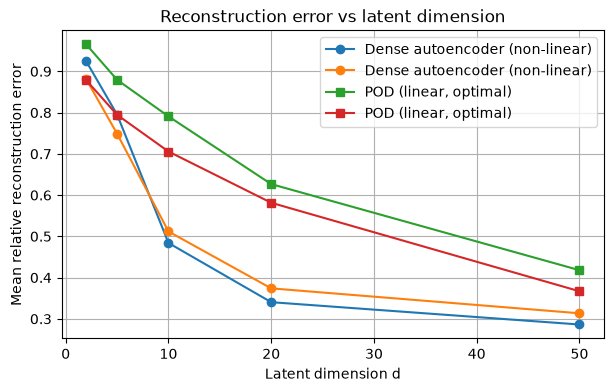

In [11]:
# =========================================================
# Plot reconstruction error vs latent dimension
# =========================================================

plt.figure(figsize=(7, 4))
plt.plot(latent_dims, sweep_ae_error, marker="o", label="Dense autoencoder (non-linear)")
plt.plot(latent_dims, sweep_pod_error, marker="s", label="POD (linear, optimal)")
plt.xlabel("Latent dimension d")
plt.ylabel("Mean relative reconstruction error")
plt.title("Reconstruction error vs latent dimension")
plt.legend()
plt.grid(True)
plt.show()


The gap between the two curves is the practical payoff of non-linear
dimensionality reduction: at low `d`, the autoencoder's non-linear encoder/decoder
can represent structures that a linear POD basis of the same rank cannot. As `d`
grows, POD -- being the optimal linear approximation -- tends to catch up, since
there is less "non-linear structure" left to exploit relative to the noise floor of
the discretization.


# 7. Save the Reference Autoencoder

We keep the `d = 20` autoencoder from the sweep above for the latent-space
analysis in the rest of this notebook, and save it for later reuse.


In [12]:
# =========================================================
# Save the reference (d = 20) dense autoencoder
# =========================================================

latent_dim = 20

ref_model_name = f"dense_ae_ref_d{latent_dim}"

dense_autoencoder.save(model_dir / f"{ref_model_name}.keras")
dense_encoder.save(model_dir / f"{ref_model_name}_encoder.keras")
dense_decoder.save(model_dir / f"{ref_model_name}_decoder.keras")

print("Reference autoencoder saved to:", model_dir)


Reference autoencoder saved to: ../models/02_latent_space_and_vae


# 8. Visualize the Latent Space

We encode the **full** dataset (not just validation) into its latent
representation, `z = encoder(v)`, and look at how the first two latent
coordinates evolve over time, as a trajectory. As a point of comparison, we do
the same with the first two POD temporal coefficients (rows of `vh` in Section
6, scaled by their singular values), since both are 2D summaries of the same
underlying dynamics -- one non-linear, one linear.


In [13]:
# =========================================================
# Encode the full dataset into the latent space
# =========================================================

z = dense_encoder.predict(v, verbose=0)
print("Latent representation shape:", z.shape)

# First two POD temporal coefficients, scaled by their singular values
pod_coeffs = (np.diag(s[:2]) @ vh[:2]).T
print("POD temporal coefficients shape:", pod_coeffs.shape)


Latent representation shape: (1000, 10)
POD temporal coefficients shape: (1000, 2)


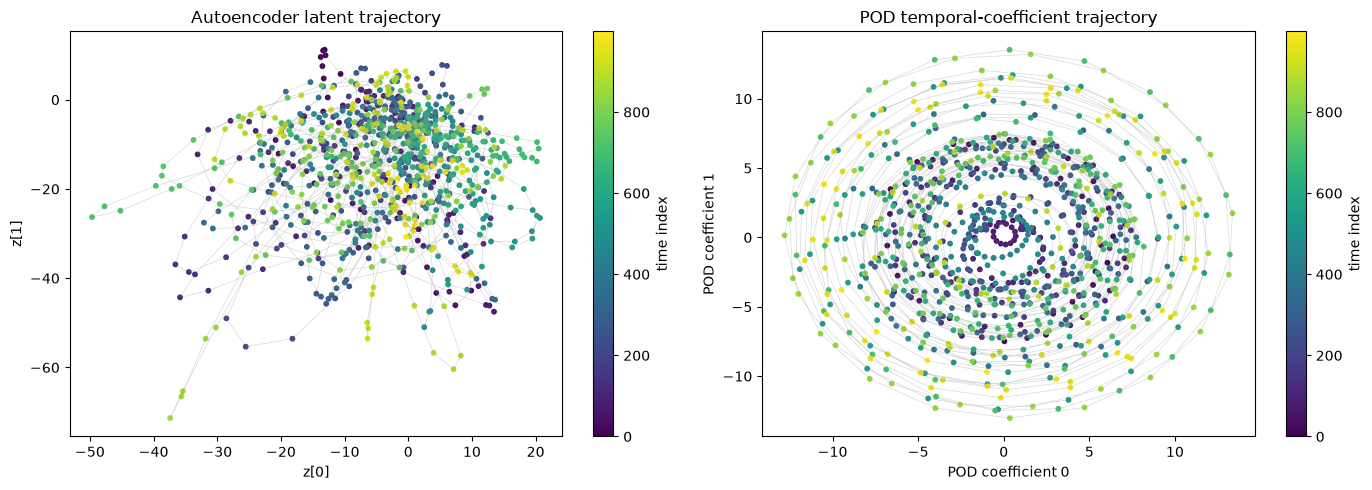

In [14]:
# =========================================================
# Plot both trajectories in their first two coordinates
# =========================================================

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sc0 = ax[0].scatter(z[:, 0], z[:, 1], c=np.arange(n_t), cmap="viridis", s=10)
ax[0].plot(z[:, 0], z[:, 1], color="gray", alpha=0.3, linewidth=0.5)
ax[0].set_xlabel("z[0]")
ax[0].set_ylabel("z[1]")
ax[0].set_title("Autoencoder latent trajectory")
fig.colorbar(sc0, ax=ax[0], label="time index")

sc1 = ax[1].scatter(pod_coeffs[:, 0], pod_coeffs[:, 1], c=np.arange(n_t), cmap="viridis", s=10)
ax[1].plot(pod_coeffs[:, 0], pod_coeffs[:, 1], color="gray", alpha=0.3, linewidth=0.5)
ax[1].set_xlabel("POD coefficient 0")
ax[1].set_ylabel("POD coefficient 1")
ax[1].set_title("POD temporal-coefficient trajectory")
fig.colorbar(sc1, ax=ax[1], label="time index")

fig.tight_layout()
plt.show()


Both trajectories describe the same underlying dynamics of the flow, but the
autoencoder's latent space is under no obligation to align its axes with any
particular physical meaning (unlike POD modes, which are ordered by energy content
and orthogonal by construction). The autoencoder's `z[0]`/`z[1]` may mix several
POD modes together, or use the latent space non-linearly (e.g. along a curved
manifold rather than straight axes).


# 9. Latent Space Interpolation

A simple way to probe whether the latent space is smooth is to linearly
interpolate between the latent codes of two snapshots and decode the
intermediate points. If the decoder produces physically plausible,
smoothly-varying intermediate fields, the latent space is a reasonable
continuous parametrization of the flow; if it produces unphysical artifacts,
the manifold learned by the autoencoder is not well-behaved.


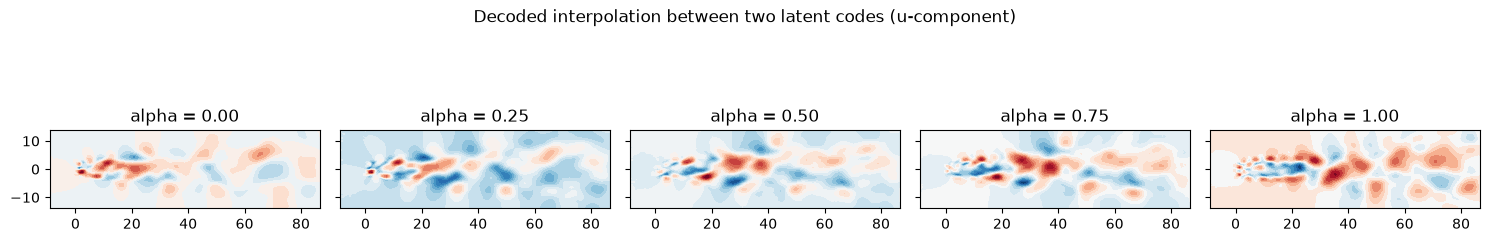

In [15]:
# =========================================================
# Interpolate between the latent codes of two snapshots
# =========================================================

idx_a, idx_b = 0, n_t - 1

z_a = dense_encoder.predict(v[idx_a:idx_a + 1], verbose=0)[0]
z_b = dense_encoder.predict(v[idx_b:idx_b + 1], verbose=0)[0]

n_steps = 5
alphas = np.linspace(0.0, 1.0, n_steps)

z_interp = np.stack([(1 - a) * z_a + a * z_b for a in alphas])
v_interp = dense_decoder.predict(z_interp, verbose=0)

fig, ax = plt.subplots(1, n_steps, sharex=True, sharey=True, figsize=(3 * n_steps, 3))

plt.set_cmap("RdBu_r")

for i, a in enumerate(alphas):
    ax[i].contourf(xx, yy, v_interp[i, :, :, 0], levels=20)
    ax[i].set_title(f"alpha = {a:.2f}")
    ax[i].set_aspect("equal")

fig.suptitle("Decoded interpolation between two latent codes (u-component)")
fig.tight_layout()
plt.show()


# 10. Variational Autoencoders (VAE)

Everything so far encodes each input to a single point `z` in latent space, with no
constraint on how that space is organized. A **Variational Autoencoder** instead
encodes each input to a *distribution* over latent space -- a mean $\mu$ and a
log-variance $\log\sigma^2$ -- and:

1. samples $z$ from that distribution using the reparameterization trick,
   $z = \mu + \sigma \odot \epsilon$, $\epsilon \sim \mathcal{N}(0, I)$, so that
   gradients can still flow through the sampling step;
2. regularizes the latent distribution towards a standard normal prior
   $\mathcal{N}(0, I)$ via a KL-divergence penalty.

The training loss becomes

$$
\mathcal{L} = \mathcal{L}_{\text{rec}}(v, \hat v) + \beta \cdot D_{\mathrm{KL}}\!\left(
\mathcal{N}(\mu, \sigma^2) \,\|\, \mathcal{N}(0, I)\right),
$$

where $\beta$ trades off reconstruction accuracy against how close the latent
space is packed to the prior. A latent space regularized this way is smoother and
can be **sampled from directly** (draw $z \sim \mathcal{N}(0, I)$ and decode it) to
generate new, synthetic flow fields -- something the plain autoencoders of Stage 1
and Sections 5-9 above cannot do in a principled way.


Note: KL means the Kullback-Leibler divergence. It is a measure of how much an approximating probability distribution Q is different from a true probability distribution P


# 11. VAE Building Blocks

The encoder now outputs `z_mean` and `z_log_var` instead of a single latent
vector, and a `Sampling` layer implements the reparameterization trick. The
decoder is unchanged in structure (`create_dense_decoder()` from Section 5).


In [16]:
# =========================================================
# VAE encoder (outputs z_mean, z_log_var, z) and Sampling layer
# =========================================================


class Sampling(tf.keras.layers.Layer):
    """
    Reparameterization trick: z = z_mean + exp(0.5 * z_log_var) * epsilon,
    with epsilon ~ N(0, I). Sampling this way keeps the operation
    differentiable with respect to z_mean and z_log_var.
    """

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.keras.backend.random_normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


def create_vae_encoder(
    input_shape,
    latent_dim,
    hidden_units=512,
    dropout_rate=0.1,
    activation="relu"
):
    """
    Create a probabilistic dense encoder for the VAE.

    Returns z_mean, z_log_var (both R^d), and a sampled z via the
    reparameterization trick.
    """

    inputs = tf.keras.layers.Input(shape=input_shape)

    x = tf.keras.layers.Flatten()(inputs)
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)

    z_mean = tf.keras.layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = tf.keras.layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling()([z_mean, z_log_var])

    encoder = tf.keras.Model(
        inputs, [z_mean, z_log_var, z], name="vae_encoder"
    )

    return encoder


In [17]:
# =========================================================
# Full VAE model: encoder + decoder + reconstruction/KL losses
# =========================================================


class VAE(tf.keras.Model):
    """
    Wraps a probabilistic encoder and a decoder into a trainable VAE model.

    add_loss() is used so that the reconstruction and KL terms are tracked
    and combined automatically by model.fit(), without needing custom
    target tensors for the KL term.
    """

    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta

        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

    def train_step(self, data):
        x, y = data

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(x)
            reconstruction = self.decoder(z)

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.square(y - reconstruction), axis=[1, 2, 3]
                )
            )

            kl_loss = -0.5 * (
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
            )
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))

            total_loss = reconstruction_loss + self.beta * kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        x, y = data

        z_mean, z_log_var, z = self.encoder(x)
        reconstruction = self.decoder(z)

        reconstruction_loss = tf.reduce_mean(
            tf.reduce_sum(tf.square(y - reconstruction), axis=[1, 2, 3])
        )
        kl_loss = -0.5 * (
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
        )
        kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))

        total_loss = reconstruction_loss + self.beta * kl_loss

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {m.name: m.result() for m in self.metrics}


# 12. Assemble, Train and Save the VAE

`beta` controls how strongly the latent space is pulled towards the standard
normal prior. A small `beta` behaves closer to a plain autoencoder (good
reconstruction, less structured latent space); a large `beta` produces a
smoother, more sampleable latent space at the cost of reconstruction accuracy.
We start with `beta = 1e-3`, a common starting point when the reconstruction
term is a raw sum-of-squares (see Experiment 3 to explore this trade-off).


In [18]:
# =========================================================
# Assemble the VAE
# =========================================================

vae_latent_dim = 10
beta = 1e-3

vae_encoder = create_vae_encoder(input_shape, latent_dim=vae_latent_dim)
vae_decoder = create_dense_decoder(input_shape, latent_dim=vae_latent_dim)

vae_encoder.summary()
vae_decoder.summary()

vae = VAE(vae_encoder, vae_decoder, beta=beta)
vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3))


Model: "vae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_15      │ (None, 128, 64,   │          0 │ -                 │
│ (InputLayer)        │ 2)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_5 (Flatten) │ (None, 16384)     │          0 │ input_layer_15[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 512)       │  8,389,120 │ flatten_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 512)       │          0 │ dense_20[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 10)        │      5,130 │ dropout_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 10)        │      5,130 │ dropout_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 10)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,399,380 (32.04 MB)

 Trainable params: 8,399,380 (32.04 MB)

 Non-trainable params: 0 (0.00 B)

Model: "dense_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 512)            │         5,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 16384)          │     8,404,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_5 (Reshape)             │ (None, 128, 64, 2)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,410,624 (32.08 MB)

 Trainable params: 8,410,624 (32.08 MB)

 Non-trainable params: 0 (0.00 B)

**Hook before the VAE training cell.** A snapshot collector for the training animation, so it comes from the base VAE training (no second run): after every epoch the reconstruction and KL losses, the reconstruction of the last validation snapshot from `z_mean` and three fields decoded from fixed prior draws (evaluation only; the draws come from their own generator). The training cell adds it, with the checkpoints, to the notebook's callbacks.

In [19]:
from pathlib import Path
anim_true = v_val[-1:]; anim_zs = np.random.default_rng(7).normal(size=(3, vae_latent_dim)).astype("float32")
class AnimSnapshots(tf.keras.callbacks.Callback):
    def __init__(self): super().__init__(); self.snaps = []; self.hist = []
    def _snap(self, e):
        zm = self.model.encoder(anim_true, training=False)[0]
        self.snaps.append(dict(epoch=e, rec=self.model.decoder(zm, training=False).numpy()[0],
                               gen=self.model.decoder(anim_zs, training=False).numpy(), hist=list(self.hist)))
    def on_train_begin(self, logs=None): self._snap(0)
    def on_epoch_end(self, epoch, logs=None):
        self.hist.append((logs.get("reconstruction_loss", np.nan), logs.get("kl_loss", np.nan), logs.get("val_loss", np.nan))); self._snap(epoch + 1)
ANIM_CB = AnimSnapshots()
def ex_base_callbacks(name): return ex_ckpt_callbacks(name, 600) + [ANIM_CB]

In [20]:
# =========================================================
# Train the VAE
# =========================================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=8,
    min_lr=1e-6
)

history_vae = vae.fit(
    v_trn,
    v_trn,
    validation_data=(v_val, v_val),
    epochs=600,
    batch_size=32,
    # [original] callbacks=[early_stopping, reduce_lr],
    callbacks=[early_stopping, reduce_lr] + ex_base_callbacks("vae"),  # added: checkpoints and animation snapshots
    verbose=2
)


Epoch 1/600


25/25 - 2s - 96ms/step - kl_loss: 28.8913 - loss: 312.9599 - reconstruction_loss: 312.9310 - val_kl_loss: 58.3397 - val_loss: 259.3312 - val_reconstruction_loss: 259.2729 - learning_rate: 1.0000e-03


Epoch 2/600


25/25 - 1s - 27ms/step - kl_loss: 69.0271 - loss: 227.3268 - reconstruction_loss: 227.2577 - val_kl_loss: 88.8289 - val_loss: 221.1925 - val_reconstruction_loss: 221.1036 - learning_rate: 1.0000e-03


Epoch 3/600


...

25/25 - 0s - 15ms/step - kl_loss: 1086.7731 - loss: 12.9695 - reconstruction_loss: 11.8827 - val_kl_loss: 1031.0795 - val_loss: 85.4735 - val_reconstruction_loss: 84.4424 - learning_rate: 3.9063e-06


Epoch 237/600


25/25 - 0s - 15ms/step - kl_loss: 1086.7985 - loss: 12.9680 - reconstruction_loss: 11.8812 - val_kl_loss: 1031.1169 - val_loss: 85.4775 - val_reconstruction_loss: 84.4464 - learning_rate: 3.9063e-06


Epoch 238/600


25/25 - 0s - 15ms/step - kl_loss: 1086.8347 - loss: 12.9666 - reconstruction_loss: 11.8797 - val_kl_loss: 1031.1611 - val_loss: 85.4748 - val_reconstruction_loss: 84.4436 - learning_rate: 3.9063e-06


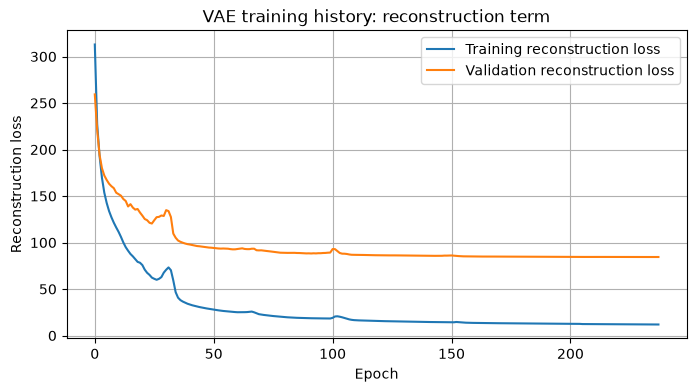

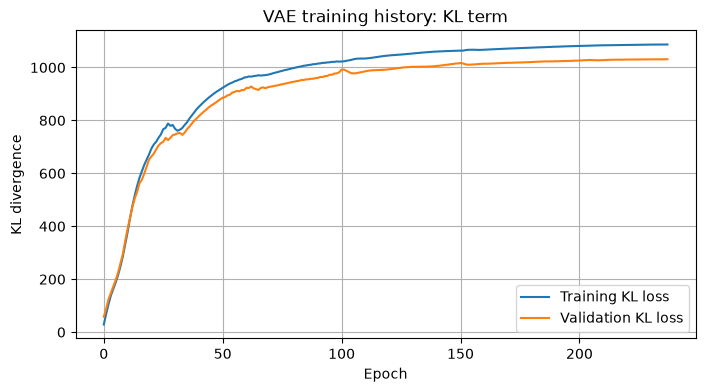

In [21]:
# =========================================================
# Plot training history
# =========================================================

plt.figure(figsize=(8, 4))
plt.plot(history_vae.history["reconstruction_loss"], label="Training reconstruction loss")
plt.plot(history_vae.history["val_reconstruction_loss"], label="Validation reconstruction loss")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction loss")
plt.title("VAE training history: reconstruction term")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history_vae.history["kl_loss"], label="Training KL loss")
plt.plot(history_vae.history["val_kl_loss"], label="Validation KL loss")
plt.xlabel("Epoch")
plt.ylabel("KL divergence")
plt.title("VAE training history: KL term")
plt.legend()
plt.grid(True)
plt.show()


## Is reconstruction always a sum of modes?

**For POD, yes.** The cell above reconstructs the reference field as an
explicit sum of the first `d` spatial modes weighted by their temporal
coefficients, and the result matches the true field closely (up to the
truncation error from using only `d` modes). This additive reconstruction is
literally the definition of the decomposition.

**For the AE, no.** The cell decodes the same latent vector two different
ways:

- **Correct**: pass the full latent vector through the decoder in a single
  forward pass.
- **Naive sum**: decode each latent dimension's true value separately (one at
  a time, from the center of the latent space), then add up each dimension's
  individual effect.

These two results differ (`nonlinearity_gap` above is rarely close to zero),
because the decoder is a **non-linear** function:

$$
\text{decoder}(z_1) + \text{decoder}(z_2) + \dots \;\neq\; \text{decoder}(z_1 + z_2 + \dots)
$$

**Summary:** for POD, the modes *are* the building blocks -- summation is how
reconstruction works. For the AE (and the VAE), the full latent vector,
decoded all at once, is what encodes the field; summing individual
per-dimension effects is not a valid reconstruction method, only a diagnostic
of what each latent direction does on its own.

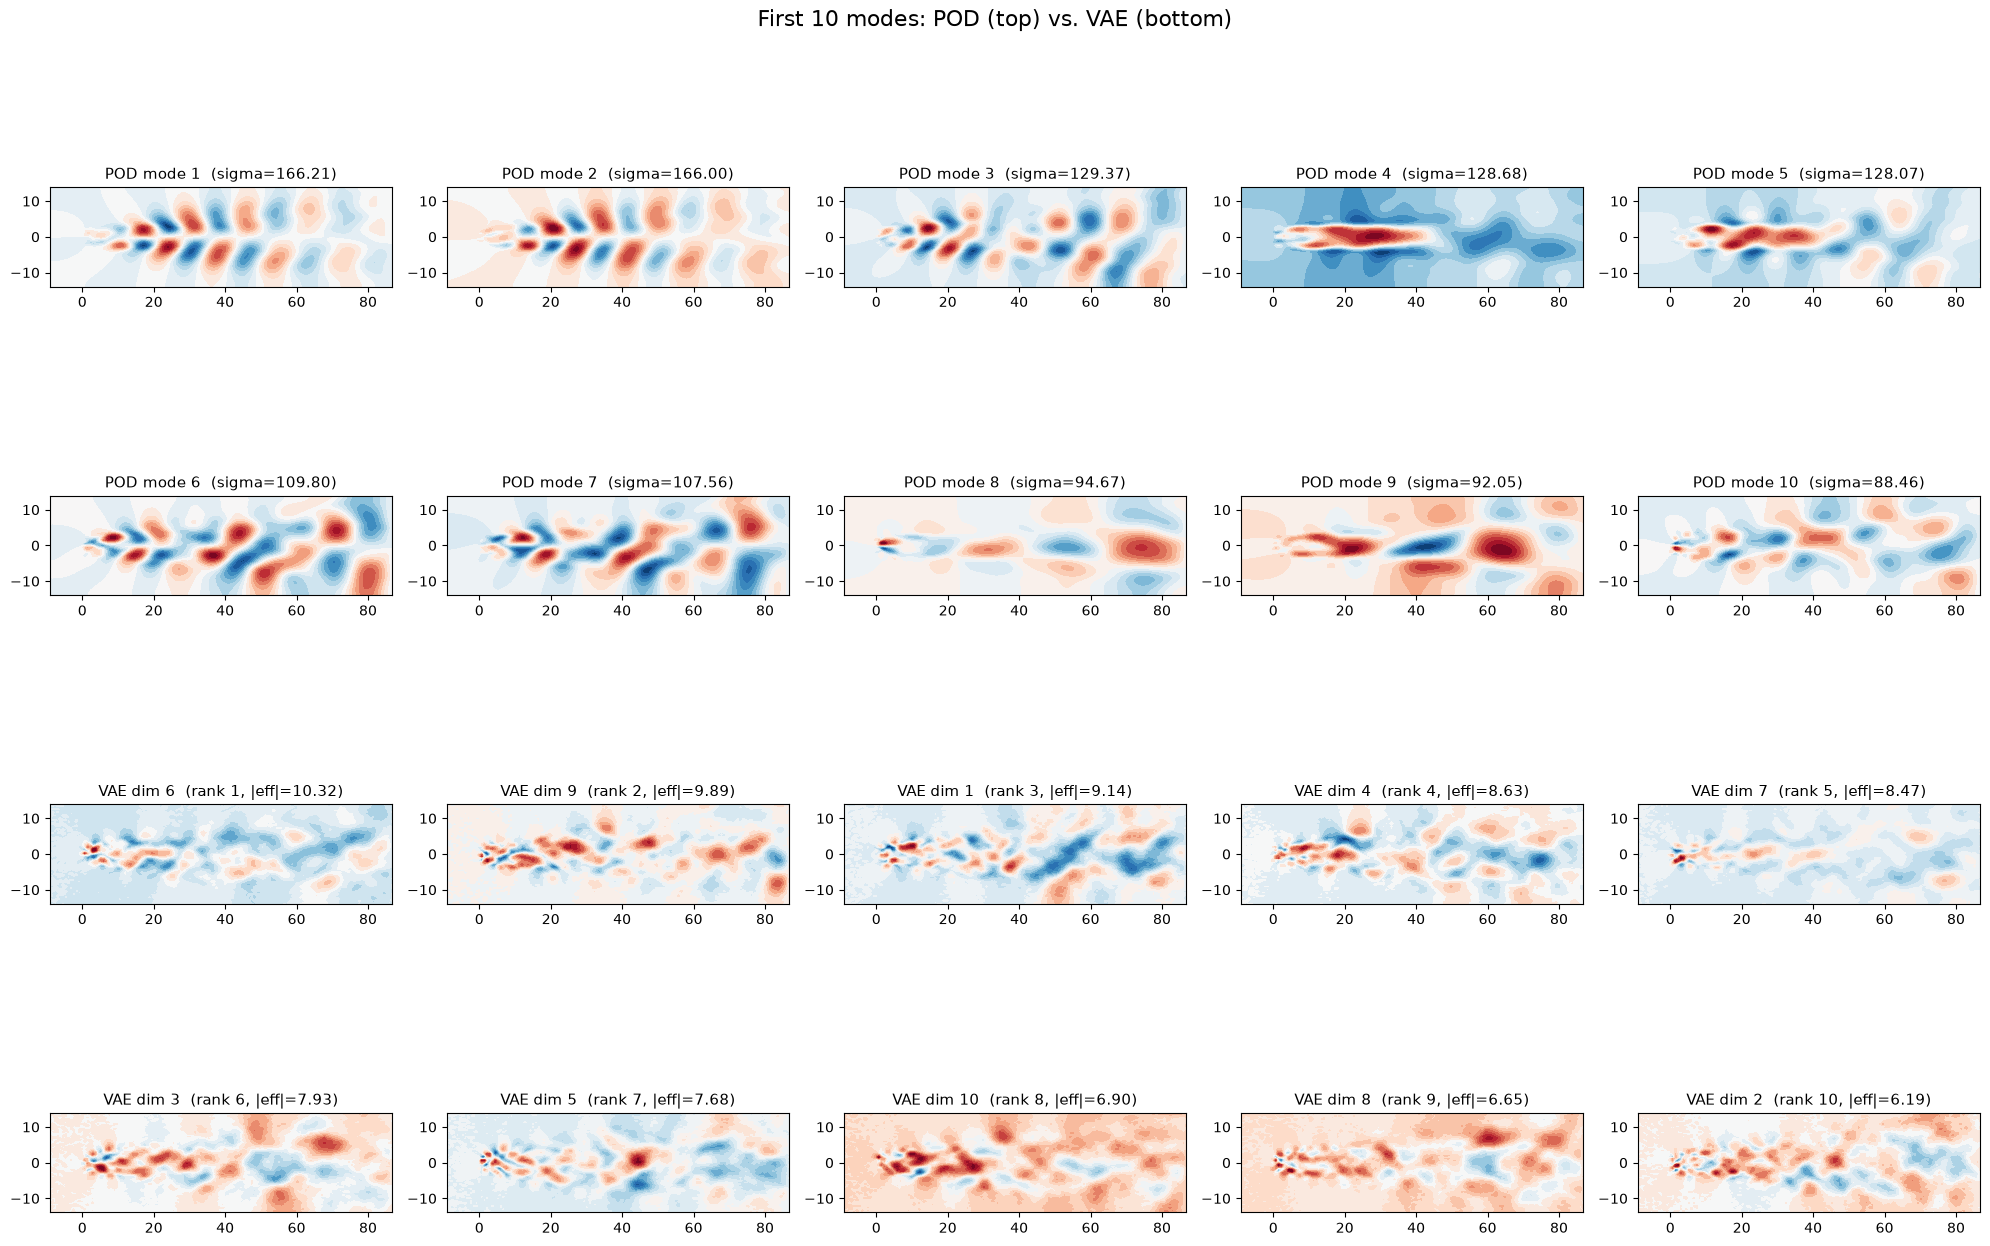

POD (sum of 10 modes) relative error:              0.7921
VAE, correct (single decode pass) relative error:   0.5630
VAE, naive sum of per-dimension effects, error:     0.9719


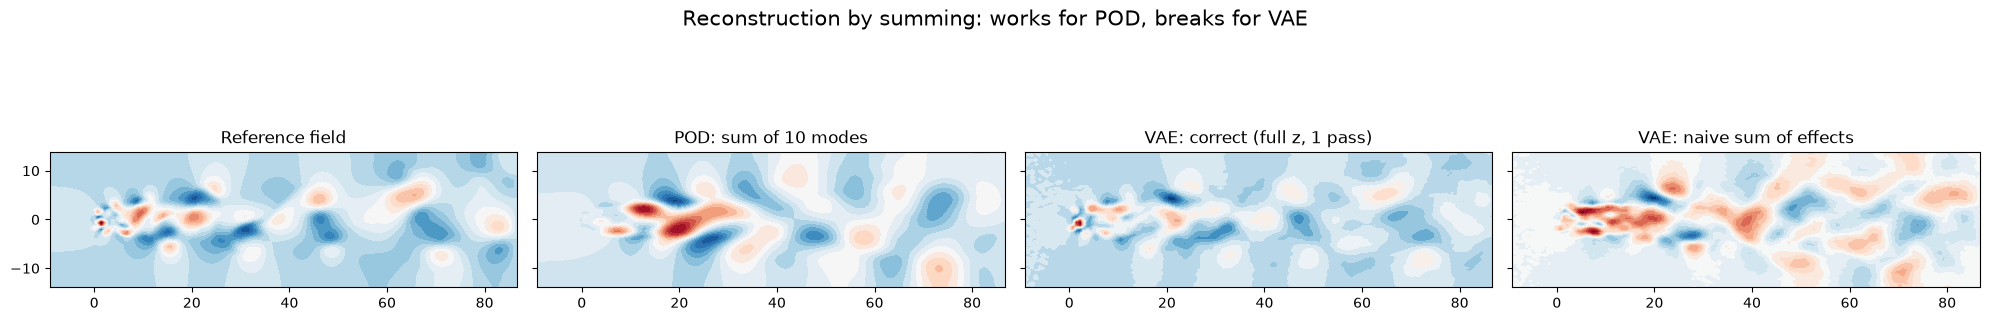

In [22]:
# =========================================================
# POD vs. VAE: first 10 modes, then reconstruction by summing
# =========================================================

n_modes_show = 10
t_idx = 0
v_reference = v[t_idx]

# ---------- Compute the 10 POD modes ----------
pod_mode_fields = [U[:, i].reshape((n_x, n_y, n_v)) for i in range(n_modes_show)]

# ---------- Compute the 10 "VAE modes" (marginal effect per latent dim) ----------
z_mean_all, z_log_var_all, _ = vae_encoder.predict(v, verbose=0)
z_center = z_mean_all.mean(axis=0)
z_std = z_mean_all.std(axis=0)
vae_baseline = vae_decoder.predict(z_center[None, :], verbose=0)[0]

vae_mode_fields = []
vae_mode_norms = []
for i in range(vae_latent_dim):
    z_perturbed = z_center.copy()
    z_perturbed[i] += 2 * z_std[i]
    field = vae_decoder.predict(z_perturbed[None, :], verbose=0)[0] - vae_baseline
    vae_mode_fields.append(field)
    vae_mode_norms.append(np.linalg.norm(field))
vae_order = np.argsort(vae_mode_norms)[::-1][:n_modes_show]

# ==========================================================
# Figure 1: first 10 modes, POD on top, VAE below
# ==========================================================
fig, axes = plt.subplots(4, 5, figsize=(20, 14))
plt.set_cmap("RdBu_r")

for i in range(n_modes_show):
    row, col = divmod(i, 5)
    ax = axes[row, col]
    ax.contourf(xx, yy, pod_mode_fields[i][:, :, 0], levels=20)
    ax.set_title(f"POD mode {i+1}  (sigma={s[i]:.2f})", fontsize=11)
    ax.set_aspect("equal")

for rank, idx in enumerate(vae_order):
    row, col = divmod(rank, 5)
    ax = axes[row + 2, col]
    ax.contourf(xx, yy, vae_mode_fields[idx][:, :, 0], levels=20)
    ax.set_title(f"VAE dim {idx+1}  (rank {rank+1}, |eff|={vae_mode_norms[idx]:.2f})", fontsize=11)
    ax.set_aspect("equal")

fig.suptitle("First 10 modes: POD (top) vs. VAE (bottom)", fontsize=16)
fig.tight_layout()
plt.show()

# ==========================================================
# Reconstruction by summing: works for POD, breaks for VAE
# ==========================================================

# POD: sum of the first d modes (this genuinely works)
d = 10
v_pod_sum = np.zeros_like(v_reference)
for i in range(d):
    coeff_temporal = s[i] * vh[i, t_idx]
    v_pod_sum = v_pod_sum + coeff_temporal * pod_mode_fields[i]

# VAE, correct: full latent vector, single decoder pass
z_real = vae_encoder.predict(v[t_idx:t_idx + 1], verbose=0)[0]  # z_mean of this snapshot
v_vae_correct = vae_decoder.predict(z_real, verbose=0)[0]

# VAE, naive sum: decode each dimension's true value separately, add effects up
v_vae_sum = vae_baseline.copy()
for i in range(vae_latent_dim):
    z_partial = z_center.copy()
    z_partial[i] = z_real[0, i]
    effect_i = vae_decoder.predict(z_partial[None, :], verbose=0)[0] - vae_baseline
    v_vae_sum = v_vae_sum + effect_i

pod_error = np.linalg.norm(v_pod_sum - v_reference) / np.linalg.norm(v_reference)
vae_correct_error = np.linalg.norm(v_vae_correct - v_reference) / np.linalg.norm(v_reference)
vae_sum_error = np.linalg.norm(v_vae_sum - v_reference) / np.linalg.norm(v_reference)

print(f"POD (sum of {d} modes) relative error:              {pod_error:.4f}")
print(f"VAE, correct (single decode pass) relative error:   {vae_correct_error:.4f}")
print(f"VAE, naive sum of per-dimension effects, error:     {vae_sum_error:.4f}")

fig, ax = plt.subplots(1, 4, figsize=(20, 4), sharex=True, sharey=True)
plt.set_cmap("RdBu_r")

fields = [
    (v_reference[:, :, 0], "Reference field"),
    (v_pod_sum[:, :, 0], f"POD: sum of {d} modes"),
    (v_vae_correct[:, :, 0], "VAE: correct (full z, 1 pass)"),
    (v_vae_sum[:, :, 0], "VAE: naive sum of effects"),
]
for a, (field, title) in zip(ax, fields):
    a.contourf(xx, yy, field, levels=20)
    a.set_title(title, fontsize=12)
    a.set_aspect("equal")

fig.suptitle("Reconstruction by summing: works for POD, breaks for VAE", fontsize=15)
fig.tight_layout()
plt.show()

In [23]:
# =========================================================
# Save the trained VAE encoder and decoder
# =========================================================

vae_model_name = f"vae_d{vae_latent_dim}"

vae_encoder.save(model_dir / f"{vae_model_name}_encoder.keras")
vae_decoder.save(model_dir / f"{vae_model_name}_decoder.keras")

run_metadata = {
    "model_name": vae_model_name,
    "task": "variational autoencoder",
    "latent_dim": vae_latent_dim,
    "beta": beta,
    "final_reconstruction_loss": float(history_vae.history["reconstruction_loss"][-1]),
    "final_val_reconstruction_loss": float(history_vae.history["val_reconstruction_loss"][-1]),
    "final_kl_loss": float(history_vae.history["kl_loss"][-1]),
}

with open(model_dir / f"{vae_model_name}_metadata.json", "w") as f:
    json.dump(run_metadata, f, indent=4)

print("VAE encoder/decoder saved to:", model_dir)


VAE encoder/decoder saved to: ../models/02_latent_space_and_vae


# 13. Evaluate the VAE: Reconstruction vs the Standard Autoencoder

We compare the VAE's reconstruction quality (using the *mean* `z_mean`, not a
random sample, so the comparison is deterministic) against the standard dense
autoencoder from Section 6-7 at the same latent dimension.


In [24]:
# =========================================================
# Compare VAE and standard autoencoder reconstruction error
# =========================================================

z_mean_val, z_log_var_val, _ = vae_encoder.predict(v_val, verbose=0)
v_val_rec_vae = vae_decoder.predict(z_mean_val, verbose=0)

vae_error = relative_reconstruction_error(v_val, v_val_rec_vae)

print(f"Reconstruction error comparison (latent dimension d = {vae_latent_dim}):")
print("  Standard dense autoencoder:", relative_reconstruction_error(
    v_val, dense_autoencoder.predict(v_val, verbose=0)
))
print("  VAE (deterministic, z_mean):", vae_error)


Reconstruction error comparison (latent dimension d = 10):
  Standard dense autoencoder: [0.48394209 0.51178975]
  VAE (deterministic, z_mean): [0.42637225 0.46015964]


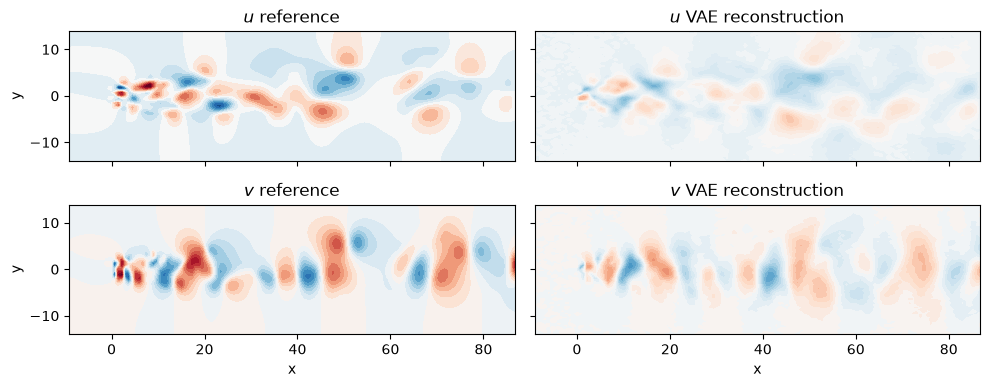

In [25]:
# =========================================================
# Visualize one validation snapshot: reference vs VAE reconstruction
# =========================================================

idx = -1

fig, ax = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(10, 4))

plt.set_cmap("RdBu_r")

vmin0, vmax0 = v_val[idx, :, :, 0].min(), v_val[idx, :, :, 0].max()
vmin1, vmax1 = v_val[idx, :, :, 1].min(), v_val[idx, :, :, 1].max()

ax[0, 0].contourf(xx, yy, v_val[idx, :, :, 0], levels=20, vmin=vmin0, vmax=vmax0)
ax[1, 0].contourf(xx, yy, v_val[idx, :, :, 1], levels=20, vmin=vmin1, vmax=vmax1)

ax[0, 1].contourf(xx, yy, v_val_rec_vae[idx, :, :, 0], levels=20, vmin=vmin0, vmax=vmax0)
ax[1, 1].contourf(xx, yy, v_val_rec_vae[idx, :, :, 1], levels=20, vmin=vmin1, vmax=vmax1)

ax[0, 0].set_ylabel("y")
ax[1, 0].set_ylabel("y")
ax[1, 0].set_xlabel("x")
ax[1, 1].set_xlabel("x")

ax[0, 0].set_title(r"$u$ reference")
ax[1, 0].set_title(r"$v$ reference")
ax[0, 1].set_title(r"$u$ VAE reconstruction")
ax[1, 1].set_title(r"$v$ VAE reconstruction")

for axx in ax.flatten():
    axx.set_aspect("equal")

fig.tight_layout()
plt.show()


# 14. Sampling from the VAE Prior: Generating Synthetic Fields

Because the VAE's latent space is regularized towards $\mathcal{N}(0, I)$, we can
draw random latent vectors directly from that prior and decode them into new,
synthetic flow fields -- without needing any encoder input at all. Whether these
synthetic fields look physically plausible is itself a useful diagnostic of how
well the latent space was regularized (compare against `beta` in Section 12; see
also Experiment 3).


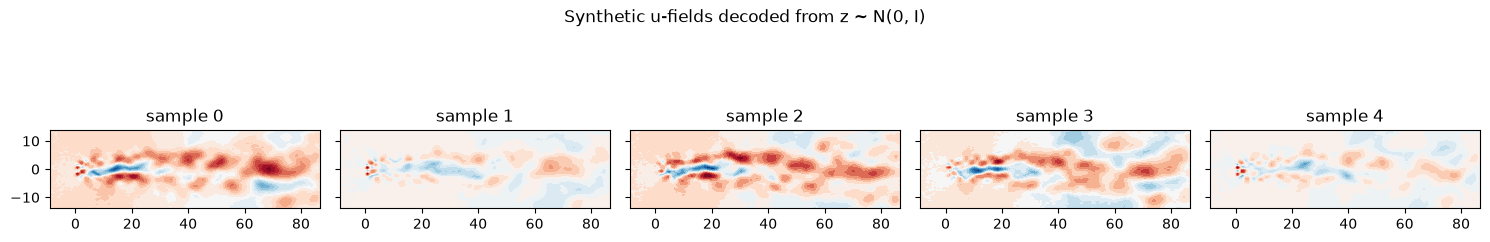

In [26]:
# =========================================================
# Sample random points from N(0, I) and decode them
# =========================================================

n_samples = 5
z_samples = np.random.normal(size=(n_samples, vae_latent_dim)).astype(np.float32)
v_samples = vae_decoder.predict(z_samples, verbose=0)

fig, ax = plt.subplots(1, n_samples, sharex=True, sharey=True, figsize=(3 * n_samples, 3))

plt.set_cmap("RdBu_r")

for i in range(n_samples):
    ax[i].contourf(xx, yy, v_samples[i, :, :, 0], levels=20)
    ax[i].set_title(f"sample {i}")
    ax[i].set_aspect("equal")

fig.suptitle("Synthetic u-fields decoded from z ~ N(0, I)")
fig.tight_layout()
plt.show()


# 15. Experiments

## Experiment 1 -- Full-budget latent dimension sweep

Section 6 uses a reduced training budget (`epochs=150`, no restart) to keep the
sweep fast. Rerun it with the full Stage 1 budget (`epochs=600`) for each `d`
and check whether the crossover point between the autoencoder and POD curves
changes.

---

## Experiment 2 -- 3D latent trajectory

Retrain the reference autoencoder in Section 6-7 with `latent_dim = 3` and
produce a 3D scatter/trajectory plot (`Axes3D` or `ax = fig.add_subplot(projection="3d")`)
analogous to Section 8. Compare it with the first three POD temporal
coefficients.

---

## Experiment 3 -- Beta sweep for the VAE

Retrain the VAE from Section 11-12 for `beta` in `[1e-5, 1e-3, 1e-1, 1.0]`.
For each value, record the reconstruction error (Section 13) and visually
inspect a handful of samples drawn from the prior (Section 14). Discuss the
reconstruction-vs-generation trade-off you observe as `beta` increases.

---

## Experiment 4 -- Convolutional VAE

Adapt `create_vae_encoder()` to use the convolutional building blocks from
Stage 1 (`create_conv_encoder()`) instead of `Flatten()` + `Dense()`, keeping
the `z_mean`/`z_log_var`/`Sampling()` outputs. Pair it with
`create_conv_decoder()` from Stage 1. Compare reconstruction error against
the dense VAE at the same `latent_dim`.

---

## Experiment 5 -- Latent-space arithmetic

Encode two very different snapshots (e.g. `v[0]` and a late-time snapshot) to
get `z_mean` for each. Instead of linear interpolation (Section 9), try simple
vector arithmetic in latent space -- e.g. decode `z_a + (z_c - z_b)` for a
third snapshot `v[c]` -- and inspect whether the result resembles a physically
plausible combination of the input fields' features.


# Experiment solutions
The five experiments of Section 15, solved with the notebook's own data (`v`, `v_trn`, `v_val`, grids `xx`, `yy`), POD (`U`, `s`, `vh`, `pod_reconstruction_error`), builders (`create_dense_encoder/decoder`, `create_vae_encoder`, `Sampling`, `VAE`) and error measure. Errors are mean relative $\ell_2$ errors (mean over the two velocity components) on the validation snapshots. Compute plan: about 12 trainings of up to 600 epochs with early stopping, roughly 40–70 minutes on the Apple GPU.

In [27]:
import time
import pandas as pd
ex_dir = Path("../results/02_latent_space_and_vae/exercises"); ex_dir.mkdir(exist_ok=True)
def ex_cbs(p_stop=20, p_lr=8):
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=p_stop, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=p_lr, min_lr=1e-6)]
EX_MAX_EPOCHS = max(30, int(300 * float(__import__('os').environ.get('EX_BUDGET_SCALE', '1'))))   # exercise budget: 300 epochs with early stopping (the base run uses 600)
def ex_train_ae(d, epochs=EX_MAX_EPOCHS, seed=0):
    tf.random.set_seed(seed); np.random.seed(seed)
    enc, dec = create_dense_encoder(input_shape, latent_dim=d), create_dense_decoder(input_shape, latent_dim=d)
    i = tf.keras.layers.Input(shape=input_shape); ae = tf.keras.Model(i, dec(enc(i)))
    ae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    h = ae.fit(v_trn, v_trn, validation_data=(v_val, v_val), epochs=epochs, batch_size=32, verbose=0, callbacks=ex_cbs())
    return enc, dec, ae, len(h.history["loss"])
def ex_train_vae(enc, dec, beta, seed=0):
    tf.random.set_seed(seed); np.random.seed(seed)
    m = VAE(enc, dec, beta=beta); m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3))
    h = m.fit(v_trn, v_trn, validation_data=(v_val, v_val), epochs=EX_MAX_EPOCHS, batch_size=32, verbose=0, callbacks=ex_cbs())
    zm = enc.predict(v_val, verbose=0)[0]
    return m, relative_reconstruction_error(v_val, dec.predict(zm, verbose=0)).mean(), len(h.history["loss"])
def ex_divergence(f):
    """Relative divergence of a velocity field (u, v) on the grid: ||du/dx + dv/dy|| / ||grad||."""
    x1, y1 = xx[:, 0], yy[0, :]
    dudx = np.gradient(f[..., 0], x1, axis=0); dvdy = np.gradient(f[..., 1], y1, axis=1)
    return np.linalg.norm(dudx + dvdy) / (np.linalg.norm(dudx) + np.linalg.norm(dvdy) + 1e-12)

## Experiment 1 — solution
The latent-dimension sweep of Section 6 rerun with the full Stage 1 budget for three of its five sizes, d = 2, 10 and 50 (experiment budget: at most three configurations): up to 600 epochs with early stopping patience 20 and learning-rate patience 8 (the notebook's sweep used 150 epochs, patience 15 and 6). The crossover is the smallest `d` at which POD becomes at least as accurate as the autoencoder.

    d     pod  ae_150  ae_600  epochs_600
0   2  0.9218  0.9024  0.9085          64
1  10  0.7483  0.4979  0.4743         151
2  50  0.3924  0.2999  0.2930         119


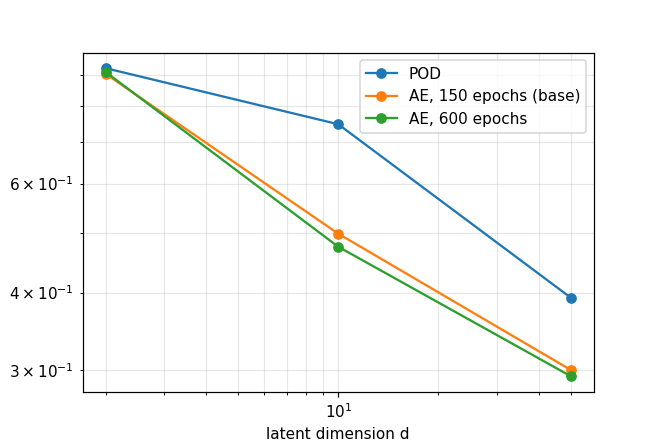

Result (Exercise 1): crossover (smallest d with POD <= AE): None with the 150-epoch budget, None with 600 epochs; AE error at 600 epochs d=2: 0.909, d=10: 0.474, d=50: 0.293


In [28]:
ex1_rows = []
for d in (2, 10, 50):   # three of the sweep's five latent sizes (exercise budget)
    k = list(latent_dims).index(d)
    _, _, ae, ep = ex_train_ae(d, epochs=600)
    ex1_rows.append(dict(d=d, pod=pod_reconstruction_error(d).mean(), ae_150=np.mean(sweep_ae_error[k]),
                         ae_600=relative_reconstruction_error(v_val, ae.predict(v_val, verbose=0)).mean(), epochs_600=ep))
ex1 = pd.DataFrame(ex1_rows); ex1.to_csv(ex_dir / "ex1_full_budget_sweep.csv", index=False); print(ex1.round(4))
def ex_cross(col):
    w = ex1[ex1.pod <= ex1[col]]; return int(w.d.min()) if len(w) else None
plt.figure(figsize=(6, 4))
for c, lab in (("pod", "POD"), ("ae_150", "AE, 150 epochs (base)"), ("ae_600", "AE, 600 epochs")):
    plt.semilogy(ex1.d, ex1[c], "o-", label=lab)
plt.xscale("log"); plt.xlabel("latent dimension d"); plt.ylabel("mean relative error"); plt.legend(); plt.grid(alpha=0.3, which="both")
plt.savefig(ex_dir / "ex1_full_budget_sweep.png", dpi=110); plt.show()
print(f"Result (Exercise 1): crossover (smallest d with POD <= AE): {ex_cross('ae_150')} with the 150-epoch budget, {ex_cross('ae_600')} with 600 epochs; "
      + "AE error at 600 epochs " + ", ".join(f"d={r.d}: {r.ae_600:.3f}" for r in ex1.itertuples()))

## Experiment 2 — solution
A dense autoencoder with `latent_dim = 3` (notebook's recipe, experiment budget of 300 epochs with early stopping), its 3-D latent trajectory over the whole time series, and the first three POD temporal coefficients scaled by their singular values, both coloured by time.

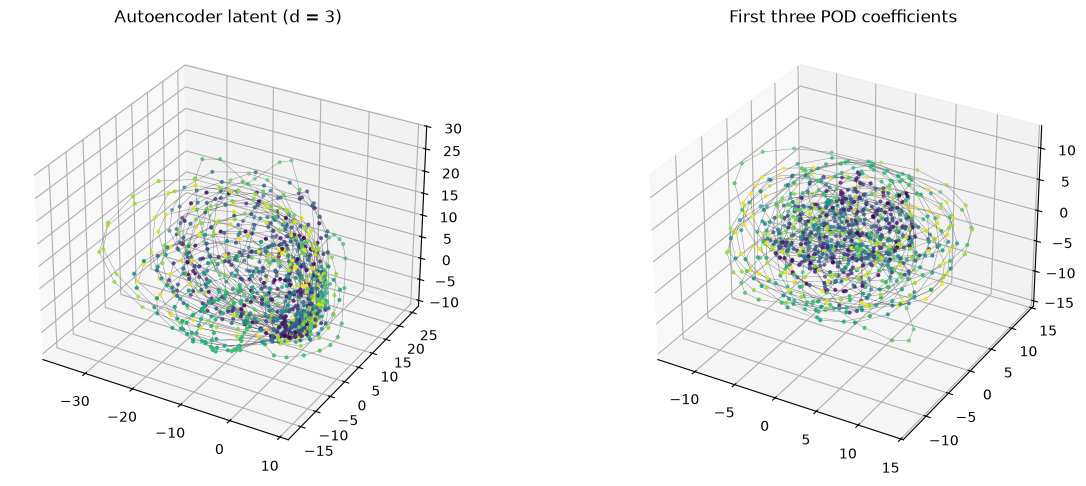

Result (Exercise 2): d=3 autoencoder validation error 0.860 vs POD-3 0.896; an affine map of the three POD coefficients explains R2 = 0.63 of the 3-D latent trajectory


In [29]:
ex2_enc, _, ex2_ae, _ = ex_train_ae(3)
ex2_z = ex2_enc.predict(v, verbose=0); ex2_pod = (np.diag(s[:3]) @ vh[:3]).T
fig = plt.figure(figsize=(13, 5))
for k, (data_, title) in enumerate(((ex2_z, "Autoencoder latent (d = 3)"), (ex2_pod, "First three POD coefficients"))):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.scatter(data_[:, 0], data_[:, 1], data_[:, 2], c=np.arange(n_t), cmap="viridis", s=4); ax.plot(data_[:, 0], data_[:, 1], data_[:, 2], lw=0.3, color="gray")
    ax.set_title(title)
plt.tight_layout(); plt.savefig(ex_dir / "ex2_3d_latent_trajectory.png", dpi=110); plt.show()
A = np.c_[ex2_pod, np.ones(n_t)]; coef, *_ = np.linalg.lstsq(A, ex2_z, rcond=None)
ex2_r2 = 1 - ((ex2_z - A @ coef) ** 2).sum() / ((ex2_z - ex2_z.mean(0)) ** 2).sum()
ex2_err = relative_reconstruction_error(v_val, ex2_ae.predict(v_val, verbose=0)).mean()
print(f"Result (Exercise 2): d=3 autoencoder validation error {ex2_err:.3f} vs POD-3 {pod_reconstruction_error(3).mean():.3f}; "
      f"an affine map of the three POD coefficients explains R2 = {ex2_r2:.2f} of the 3-D latent trajectory")

## Experiment 3 — solution
The VAE of Sections 11–12 (`vae_latent_dim = 10`, same training recipe) for β ∈ {1e-5, 1e-3, 1e-1, 1}: β = 1e-3 is the notebook's trained VAE (not retrained); the other three are trained with the experiment budget (300 epochs, early stopping). For each β: validation reconstruction error from `z_mean`, the mean KL term, and five fields decoded from the same prior draws $z \sim \mathcal{N}(0, I)$. As an objective measure of how plausible the generated fields are, their energy is compared with that of real snapshots (ratio of mean squared norms) and their relative divergence with that of real snapshots.

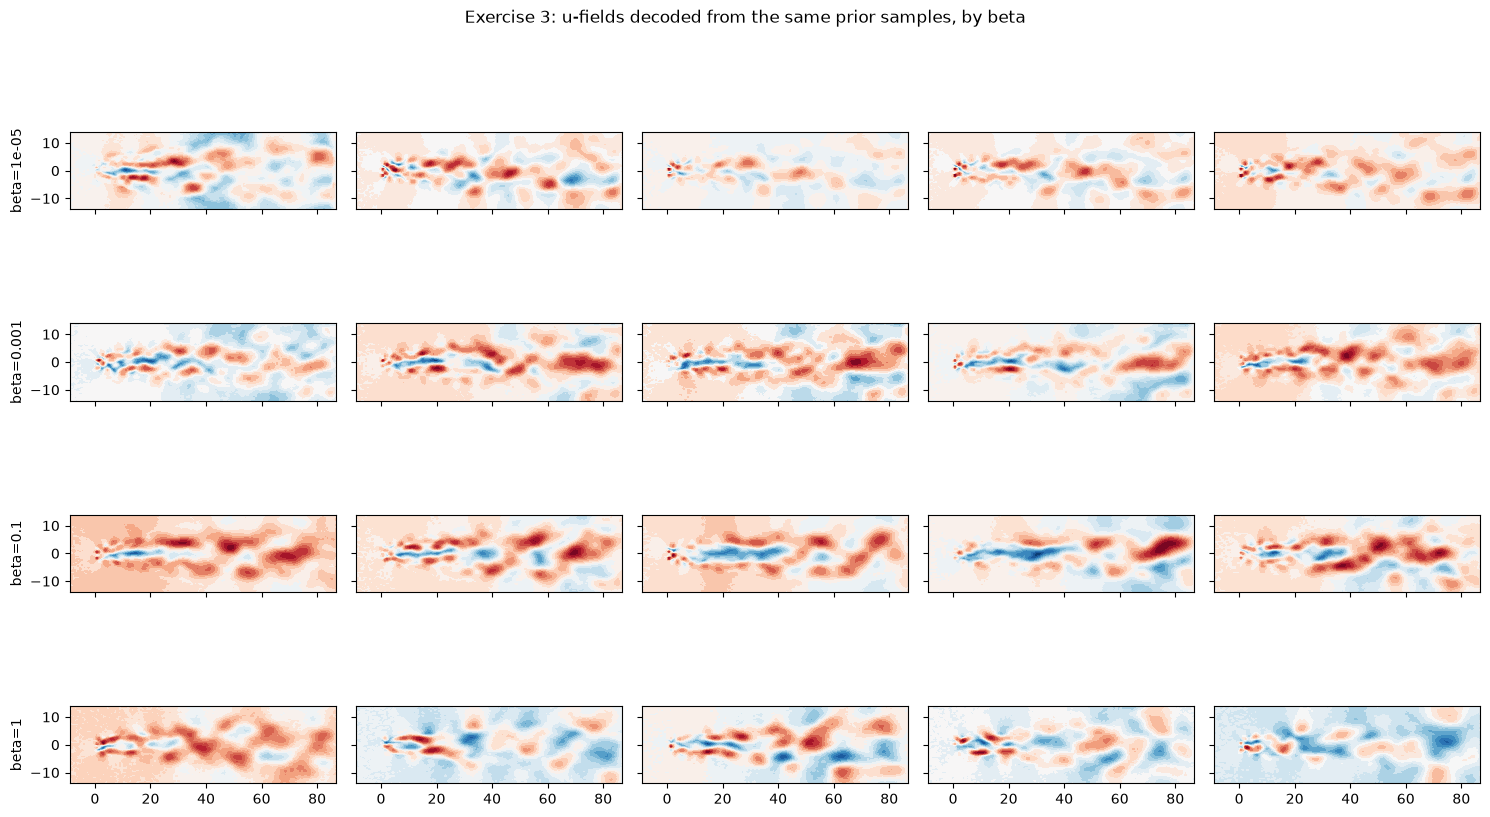

    beta  rel_error         kl  epochs  gen_energy_ratio  gen_divergence  \
0  0.000     0.4358  1544.2158     263            0.1508          0.2494   
1  0.001     0.4433  1029.7493     238            0.0446          0.2744   
2  0.100     0.4791    64.3352     129            0.1100          0.2509   
3  1.000     0.6600    30.3837      92            0.1795          0.3022   

   real_divergence  
0           0.1544  
1           0.1544  
2           0.1544  
3           0.1544  
Result (Exercise 3): beta 1e-05: error 0.436, KL 1544.2, generated/real energy 0.15; beta 0.001: error 0.443, KL 1029.7, generated/real energy 0.04; beta 0.1: error 0.479, KL 64.3, generated/real energy 0.11; beta 1: error 0.660, KL 30.4, generated/real energy 0.18


In [30]:
ex3_rows = []; ex3_zs = np.random.default_rng(0).normal(size=(5, vae_latent_dim)).astype("float32")
ex_real_div = np.mean([ex_divergence(f) for f in v[::50]]); ex_real_energy = np.mean(np.sum(v ** 2, axis=(1, 2, 3)))
fig, axes = plt.subplots(4, 5, figsize=(15, 9), sharex=True, sharey=True)
for r, b in enumerate((1e-5, 1e-3, 1e-1, 1.0)):
    if b == beta:   # the notebook's VAE of Sections 11-12
        enc, dec, m, err, ep = vae_encoder, vae_decoder, vae, float(np.mean(vae_error)), len(history_vae.history["loss"])
    else:
        enc, dec = create_vae_encoder(input_shape, latent_dim=vae_latent_dim), create_dense_decoder(input_shape, latent_dim=vae_latent_dim)
        m, err, ep = ex_train_vae(enc, dec, b)
    zm, zlv, _ = enc.predict(v_val, verbose=0)
    kl = float(np.mean(np.sum(-0.5 * (1 + zlv - zm ** 2 - np.exp(zlv)), axis=1)))
    gen = dec.predict(ex3_zs, verbose=0)
    ex3_rows.append(dict(beta=b, rel_error=err, kl=kl, epochs=ep, gen_energy_ratio=float(np.mean(np.sum(gen ** 2, axis=(1, 2, 3))) / ex_real_energy),
                         gen_divergence=float(np.mean([ex_divergence(g) for g in gen])), real_divergence=float(ex_real_div)))
    for c in range(5):
        axes[r, c].contourf(xx, yy, gen[c, :, :, 0], levels=20, cmap="RdBu_r"); axes[r, c].set_aspect("equal")
    axes[r, 0].set_ylabel(f"beta={b:g}")
fig.suptitle("Exercise 3: u-fields decoded from the same prior samples, by beta"); fig.tight_layout()
plt.savefig(ex_dir / "ex3_beta_prior_samples.png", dpi=100); plt.show()
ex3 = pd.DataFrame(ex3_rows); ex3.to_csv(ex_dir / "ex3_beta_sweep.csv", index=False); print(ex3.round(4))
print("Result (Exercise 3): " + "; ".join(f"beta {r.beta:g}: error {r.rel_error:.3f}, KL {r.kl:.1f}, generated/real energy {r.gen_energy_ratio:.2f}" for r in ex3.itertuples()))

## Experiment 4 — solution
A convolutional VAE: the encoder uses Stage 1's convolutional block (one 3×3 convolution with 32 filters and one 2×2 max-pooling, as in `create_conv_encoder()` of Stage 1) and ends in the `z_mean`/`z_log_var`/`Sampling()` outputs; the decoder is Stage 1's `create_conv_decoder()` design (dense expansion, convolution, upsampling, cropping, linear output convolution). Those builders are not in this notebook, so they are written here following Stage 1. Same `vae_latent_dim`, β and training recipe as the dense VAE of Section 12.

In [31]:
def ex_conv_vae_encoder(d, f=32):
    i = tf.keras.layers.Input(shape=input_shape)
    x = tf.keras.layers.Conv2D(f, 3, activation="relu", padding="same")(i)
    x = tf.keras.layers.Flatten()(tf.keras.layers.MaxPooling2D(2, padding="same")(x))
    zm = tf.keras.layers.Dense(d, name="z_mean")(x); zl = tf.keras.layers.Dense(d, name="z_log_var")(x)
    return tf.keras.Model(i, [zm, zl, Sampling()([zm, zl])], name="conv_vae_encoder")
def ex_conv_decoder(d, f=32):
    h, w = int(np.ceil(n_x / 2)), int(np.ceil(n_y / 2)); i = tf.keras.layers.Input(shape=(d,))
    x = tf.keras.layers.Reshape((h, w, f))(tf.keras.layers.Dense(h * w * f, activation="relu")(i))
    x = tf.keras.layers.UpSampling2D(2)(tf.keras.layers.Conv2D(f, 3, activation="relu", padding="same")(x))
    x = tf.keras.layers.Cropping2D(((0, x.shape[1] - n_x), (0, x.shape[2] - n_y)))(x)
    return tf.keras.Model(i, tf.keras.layers.Conv2D(n_v, 3, padding="same")(x), name="conv_decoder")
with tf.device("/CPU:0"):   # convolutional VAE on the CPU (device cell)
    ex4_enc, ex4_dec = ex_conv_vae_encoder(vae_latent_dim), ex_conv_decoder(vae_latent_dim)
    t0 = time.time(); _, ex4_err, ex4_ep = ex_train_vae(ex4_enc, ex4_dec, beta); ex4_t = time.time() - t0
ex4 = pd.DataFrame([dict(model="dense VAE (Section 12)", rel_error=vae_error.mean(), params=vae_encoder.count_params() + vae_decoder.count_params()),
                    dict(model="conv VAE", rel_error=ex4_err, params=ex4_enc.count_params() + ex4_dec.count_params(), epochs=ex4_ep, train_s=round(ex4_t))])
ex4.to_csv(ex_dir / "ex4_conv_vae.csv", index=False); print(ex4)
print(f"Result (Exercise 4): d={vae_latent_dim}, beta={beta:g}: validation relative error dense VAE {vae_error.mean():.4f} vs convolutional VAE {ex4_err:.4f} "
      f"({ex4.params[0]:,} vs {ex4.params[1]:,} parameters)")

                    model  rel_error    params  epochs  train_s
0  dense VAE (Section 12)   0.443266  16810004     NaN      NaN
1                conv VAE   0.438775   2042070   118.0    121.0
Result (Exercise 4): d=10, beta=0.001: validation relative error dense VAE 0.4433 vs convolutional VAE 0.4388 (16,810,004 vs 2,042,070 parameters)


## Experiment 5 — solution
Latent arithmetic with the trained VAE of Section 12: encode `v[a]`, `v[b]`, `v[c]` (a = 0, b = 500, c = the last snapshot) to their `z_mean` and decode $z_a + (z_c - z_b)$. Plausibility is checked three ways: visually; by the distance from the result to the nearest real snapshot (relative error), compared with the typical distance between consecutive real snapshots; and by its relative divergence, compared with real snapshots (the flow is incompressible, so a physical field should have the same small discrete divergence as the data).

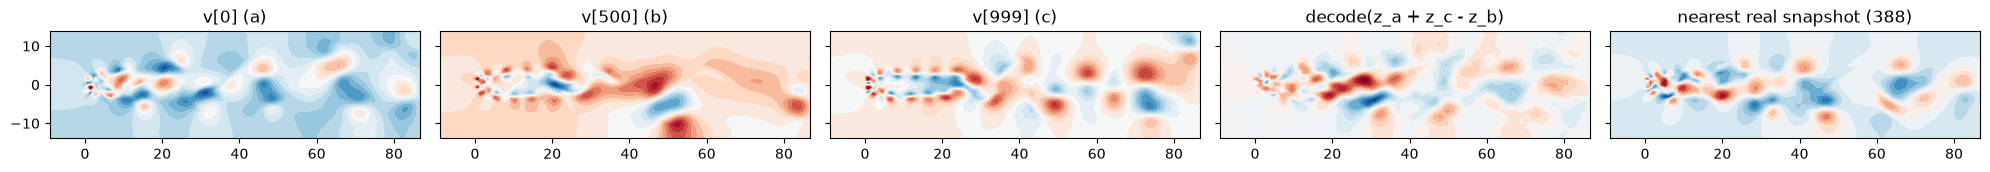

Result (Exercise 5): decoded z_a+(z_c-z_b) lies at relative distance 0.740 from the nearest real snapshot (388) (median distance between consecutive snapshots 0.478); relative divergence 0.215 vs real snapshots 0.154 and field-space arithmetic 0.189


In [32]:
ex5_a, ex5_b, ex5_c = 0, 500, n_t - 1
zab = vae_encoder.predict(v[[ex5_a, ex5_b, ex5_c]], verbose=0)[0]
ex5_field = vae_decoder.predict((zab[0] + (zab[2] - zab[1]))[None], verbose=0)[0]
ex5_lin = v[ex5_a] + (v[ex5_c] - v[ex5_b])   # the same arithmetic done directly on the fields
d_near = np.linalg.norm((v - ex5_field).reshape(n_t, -1), axis=1) / np.linalg.norm(ex5_field)
d_consec = np.median(np.linalg.norm(np.diff(v, axis=0).reshape(n_t - 1, -1), axis=1) / np.linalg.norm(v[1:].reshape(n_t - 1, -1), axis=1))
fig, ax = plt.subplots(1, 5, figsize=(20, 3.5), sharex=True, sharey=True)
for a_, (f_, t_) in zip(ax, ((v[ex5_a], f"v[{ex5_a}] (a)"), (v[ex5_b], f"v[{ex5_b}] (b)"), (v[ex5_c], f"v[{ex5_c}] (c)"),
                             (ex5_field, "decode(z_a + z_c - z_b)"), (v[int(d_near.argmin())], f"nearest real snapshot ({int(d_near.argmin())})"))):
    a_.contourf(xx, yy, f_[:, :, 0], levels=20, cmap="RdBu_r"); a_.set_title(t_); a_.set_aspect("equal")
fig.tight_layout(); plt.savefig(ex_dir / "ex5_latent_arithmetic.png", dpi=100); plt.show()
print(f"Result (Exercise 5): decoded z_a+(z_c-z_b) lies at relative distance {d_near.min():.3f} from the nearest real snapshot ({int(d_near.argmin())}) "
      f"(median distance between consecutive snapshots {d_consec:.3f}); relative divergence {ex_divergence(ex5_field):.3f} vs real snapshots {ex_real_div:.3f} "
      f"and field-space arithmetic {ex_divergence(ex5_lin):.3f}")

## Summary of the experiment solutions
- **Experiment 1:** autoencoder versus POD across latent sizes with the full training budget, and where they cross.
- **Experiment 2:** a 3-D latent trajectory next to the first three POD coefficients.
- **Experiment 3:** the β trade-off between reconstruction and the quality of prior samples.
- **Experiment 4:** a convolutional VAE against the dense VAE at the same latent size.
- **Experiment 5:** latent arithmetic and objective plausibility checks of the result.

The numbers are those printed in the `Result` lines above.

# Animation — the VAE learning the flow and its prior
The snapshots come from **the base VAE training** (hook cell before the training cell; no second run): `vae_latent_dim = 10`, β = 1e-3, Adam 1e-3, batch 32, up to 600 epochs with the notebook's early stopping and learning-rate halving. After every epoch it stores the reconstruction and KL losses, the reconstruction of the last validation snapshot from `z_mean`, and three fields decoded from fixed prior samples. Dashboard: `../animations/02_training_dashboard.mp4`; last frame: `../animations/02_final_frame.png`.

In [33]:
import pickle, time
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
anim_dir = Path("../animations"); anim_dir.mkdir(exist_ok=True)
anim_cb = ANIM_CB
pickle.dump(anim_cb.snaps, open(anim_dir / "02_snapshots.pkl", "wb"))
print(f"Base run: {len(anim_cb.snaps)-1} epochs; validation relative error {vae_error.mean():.4f}")

Base run: 238 epochs; validation relative error 0.4433


In [34]:
snaps = anim_cb.snaps; n_ep = snaps[-1]["epoch"]; tr = anim_true[0, :, :, 0]; vmin, vmax = tr.min(), tr.max()
H = np.array(snaps[-1]["hist"])
fig = plt.figure(figsize=(14, 7)); gs = fig.add_gridspec(2, 3)
axs = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2])] + [fig.add_subplot(gs[1, k]) for k in range(3)]
def anim_draw(k):
    s_ = snaps[k]
    for a in axs: a.clear()
    axs[0].contourf(xx, yy, tr, levels=30, cmap="RdBu_r", vmin=vmin, vmax=vmax); axs[0].set_title("Validation snapshot, u"); axs[0].set_aspect("equal")
    axs[1].contourf(xx, yy, s_["rec"][:, :, 0], levels=30, cmap="RdBu_r", vmin=vmin, vmax=vmax); axs[1].set_title(f"VAE reconstruction, epoch {s_['epoch']}"); axs[1].set_aspect("equal")
    h = np.array(s_["hist"]) if s_["hist"] else np.zeros((0, 3))
    if len(h):
        axs[2].semilogy(h[:, 0], label="reconstruction"); axs[2].semilogy(h[:, 1], label="KL"); axs[2].semilogy(h[:, 2], label="validation total")
    axs[2].set_xlim(0, n_ep); axs[2].set_ylim(np.nanmin(H) * 0.7, np.nanmax(H) * 1.5); axs[2].legend(fontsize=8); axs[2].set_xlabel("epoch"); axs[2].set_title("Losses"); axs[2].grid(alpha=0.3, which="both")
    for j in range(3):
        axs[3 + j].contourf(xx, yy, s_["gen"][j, :, :, 0], levels=30, cmap="RdBu_r", vmin=vmin, vmax=vmax); axs[3 + j].set_aspect("equal"); axs[3 + j].set_title(f"decoded prior sample {j+1}")
    fig.suptitle(f"Stage 2 — VAE (latent_dim {vae_latent_dim}, beta {beta:g}), base run (seed 0)"); fig.tight_layout()
anim_draw(len(snaps) - 1); fig.savefig(anim_dir / "02_final_frame.png", dpi=100)
FuncAnimation(fig, anim_draw, frames=len(snaps)).save(anim_dir / "02_training_dashboard.mp4", writer=FFMpegWriter(fps=10, bitrate=1800), dpi=90)
plt.close(fig); print(f"Animation: {len(snaps)} frames written")

/var/folders/1h/r2mbj41x5f7d80jf6t_9hx_c0000gn/T/ipykernel_88669/617219915.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2].set_xlim(0, n_ep); axs[2].set_ylim(np.nanmin(H) * 0.7, np.nanmax(H) * 1.5); axs[2].legend(fontsize=8); axs[2].set_xlabel("epoch"); axs[2].set_title("Losses"); axs[2].grid(alpha=0.3, which="both")


Animation: 239 frames written


**What the animation shows.** Top: a validation snapshot, its VAE reconstruction after each epoch, and the reconstruction, KL and validation losses. Bottom: three fields decoded from the same three prior samples $z \sim \mathcal{N}(0, I)$ at every epoch, showing when sampling from the prior starts to produce wake-like fields and how they settle as the KL term organises the latent space.

# Three-seed repeats
Every training here takes well under 15 minutes, so each is repeated with the seeds 0, 1 and 2. **Seed 0 is the base run**: the notebook's sweep and VAE above (seeds set in the import cell) and the experiment solutions (`seed=0`). For seeds 1 and 2, `tf.keras.utils.set_random_seed(seed)` sets the initial weights, dropout, the VAE's sampling noise and the batch order; data, split, settings and devices are unchanged. One cell per seed, then a summary (validation relative error, mean over u and v).

In [35]:
# Three-seed repeats: helpers
import time
def seed_ae(d, seed, epochs, p_stop, p_lr):
    tf.keras.utils.set_random_seed(seed)
    enc, dec = create_dense_encoder(input_shape, latent_dim=d), create_dense_decoder(input_shape, latent_dim=d)
    i = tf.keras.layers.Input(shape=input_shape); ae = tf.keras.Model(i, dec(enc(i)))
    ae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse"); t0 = time.time()
    h = ae.fit(v_trn, v_trn, validation_data=(v_val, v_val), epochs=epochs, batch_size=32, verbose=0, callbacks=ex_cbs(p_stop, p_lr))
    return float(relative_reconstruction_error(v_val, ae.predict(v_val, verbose=0)).mean()), len(h.history["loss"]), round(time.time() - t0, 1)
def seed_vae(enc_dec, b, seed, epochs):
    tf.keras.utils.set_random_seed(seed)
    enc, dec = enc_dec(); m = VAE(enc, dec, beta=b); m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3)); t0 = time.time()
    h = m.fit(v_trn, v_trn, validation_data=(v_val, v_val), epochs=epochs, batch_size=32, verbose=0, callbacks=ex_cbs())
    zm = enc.predict(v_val, verbose=0)[0]
    return float(relative_reconstruction_error(v_val, dec.predict(zm, verbose=0)).mean()), len(h.history["loss"]), round(time.time() - t0, 1)
dense_vae = lambda: (create_vae_encoder(input_shape, latent_dim=vae_latent_dim), create_dense_decoder(input_shape, latent_dim=vae_latent_dim))
def seed_run(seed):
    rows = []
    def add(part, config, res): rows.append(dict(seed=seed, part=part, config=config, rel_error=res[0], epochs=res[1], train_s=res[2])); print(rows[-1], flush=True)
    for d in latent_dims: add("sweep (150 epochs)", f"AE d={d}", seed_ae(d, seed, 150, 15, 6))
    add("base", f"VAE d={vae_latent_dim}, beta={beta:g}", seed_vae(dense_vae, beta, seed, 600))
    for d in (2, 10, 50): add("Exercise 1 (600 epochs)", f"AE d={d}", seed_ae(d, seed, 600, 20, 8))
    add("Exercise 2", "AE d=3", seed_ae(3, seed, EX_MAX_EPOCHS, 20, 8))
    for b in (1e-5, 1e-1, 1.0): add("Exercise 3", f"VAE beta={b:g}", seed_vae(dense_vae, b, seed, EX_MAX_EPOCHS))
    with tf.device("/CPU:0"):
        add("Exercise 4", "conv VAE", seed_vae(lambda: (ex_conv_vae_encoder(vae_latent_dim), ex_conv_decoder(vae_latent_dim)), beta, seed, EX_MAX_EPOCHS))
    return rows
seed_rows = [dict(seed=0, part="sweep (150 epochs)", config=f"AE d={d}", rel_error=float(np.mean(e))) for d, e in zip(latent_dims, sweep_ae_error)]
seed_rows.append(dict(seed=0, part="base", config=f"VAE d={vae_latent_dim}, beta={beta:g}", rel_error=float(np.mean(vae_error)), epochs=len(history_vae.history["loss"])))
seed_rows += [dict(seed=0, part="Exercise 1 (600 epochs)", config=f"AE d={r.d}", rel_error=r.ae_600, epochs=r.epochs_600) for r in ex1.itertuples()]
seed_rows.append(dict(seed=0, part="Exercise 2", config="AE d=3", rel_error=float(ex2_err)))
seed_rows += [dict(seed=0, part="Exercise 3", config=f"VAE beta={r.beta:g}", rel_error=r.rel_error, epochs=r.epochs) for r in ex3.itertuples() if r.beta != beta]
seed_rows.append(dict(seed=0, part="Exercise 4", config="conv VAE", rel_error=float(ex4_err), epochs=ex4_ep, train_s=round(ex4_t, 1)))
print(len(seed_rows), "base-run (seed 0) rows")

14 base-run (seed 0) rows


In [36]:
# Seed 1
seed_rows += seed_run(1)

{'seed': 1, 'part': 'sweep (150 epochs)', 'config': 'AE d=2', 'rel_error': 0.8936542493486279, 'epochs': 77, 'train_s': 24.9}


{'seed': 1, 'part': 'sweep (150 epochs)', 'config': 'AE d=5', 'rel_error': 0.7601985703567857, 'epochs': 103, 'train_s': 33.0}


{'seed': 1, 'part': 'sweep (150 epochs)', 'config': 'AE d=10', 'rel_error': 0.5130677240866248, 'epochs': 97, 'train_s': 31.3}


{'seed': 1, 'part': 'sweep (150 epochs)', 'config': 'AE d=20', 'rel_error': 0.35201174223441356, 'epochs': 110, 'train_s': 35.3}


{'seed': 1, 'part': 'sweep (150 epochs)', 'config': 'AE d=50', 'rel_error': 0.29513663552699887, 'epochs': 97, 'train_s': 31.4}


...

{'seed': 1, 'part': 'Exercise 2', 'config': 'AE d=3', 'rel_error': 0.8608305061751419, 'epochs': 76, 'train_s': 24.4}


{'seed': 1, 'part': 'Exercise 3', 'config': 'VAE beta=1e-05', 'rel_error': 0.426906667556212, 'epochs': 274, 'train_s': 98.4}


{'seed': 1, 'part': 'Exercise 3', 'config': 'VAE beta=0.1', 'rel_error': 0.49427019932762495, 'epochs': 113, 'train_s': 41.7}


{'seed': 1, 'part': 'Exercise 3', 'config': 'VAE beta=1', 'rel_error': 0.6333587734240709, 'epochs': 57, 'train_s': 21.4}


{'seed': 1, 'part': 'Exercise 4', 'config': 'conv VAE', 'rel_error': 0.4455056935555747, 'epochs': 127, 'train_s': 129.8}


In [37]:
# Seed 2
seed_rows += seed_run(2)

{'seed': 2, 'part': 'sweep (150 epochs)', 'config': 'AE d=2', 'rel_error': 0.9126381533749852, 'epochs': 54, 'train_s': 17.8}


{'seed': 2, 'part': 'sweep (150 epochs)', 'config': 'AE d=5', 'rel_error': 0.7693797108389437, 'epochs': 73, 'train_s': 23.7}


{'seed': 2, 'part': 'sweep (150 epochs)', 'config': 'AE d=10', 'rel_error': 0.4785584896287588, 'epochs': 131, 'train_s': 41.9}


{'seed': 2, 'part': 'sweep (150 epochs)', 'config': 'AE d=20', 'rel_error': 0.3569293923873956, 'epochs': 98, 'train_s': 31.7}


{'seed': 2, 'part': 'sweep (150 epochs)', 'config': 'AE d=50', 'rel_error': 0.2983641258743712, 'epochs': 93, 'train_s': 30.1}


...

{'seed': 2, 'part': 'Exercise 2', 'config': 'AE d=3', 'rel_error': 0.8631127307565296, 'epochs': 119, 'train_s': 38.1}


{'seed': 2, 'part': 'Exercise 3', 'config': 'VAE beta=1e-05', 'rel_error': 0.42636363355296836, 'epochs': 228, 'train_s': 82.0}


{'seed': 2, 'part': 'Exercise 3', 'config': 'VAE beta=0.1', 'rel_error': 0.49293293313374004, 'epochs': 113, 'train_s': 41.0}


{'seed': 2, 'part': 'Exercise 3', 'config': 'VAE beta=1', 'rel_error': 0.628284796377354, 'epochs': 60, 'train_s': 22.4}


{'seed': 2, 'part': 'Exercise 4', 'config': 'conv VAE', 'rel_error': 0.4481884802012227, 'epochs': 125, 'train_s': 128.9}


In [38]:
# Three-seed summary
seed_runs = pd.DataFrame(seed_rows); seed_runs.to_csv(ex_dir / "seeds_runs.csv", index=False)
seed_sum = seed_runs.groupby(["part", "config"], sort=False).rel_error.agg(["mean", "std", "min", "max", "count"]).reset_index()
seed_sum.to_csv(ex_dir / "seeds_summary.csv", index=False)
print(seed_sum.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nPOD at the same sizes (deterministic, all snapshots): " + ", ".join(f"d={d}: {np.mean(pod_reconstruction_error(d)):.4f}" for d in latent_dims))

                   part               config   mean    std    min    max  count
     sweep (150 epochs)               AE d=2 0.9029 0.0095 0.8937 0.9126      3
     sweep (150 epochs)               AE d=5 0.7672 0.0062 0.7602 0.7720      3
     sweep (150 epochs)              AE d=10 0.4965 0.0173 0.4786 0.5131      3
     sweep (150 epochs)              AE d=20 0.3554 0.0029 0.3520 0.3571      3
     sweep (150 epochs)              AE d=50 0.2978 0.0024 0.2951 0.2999      3
                   base VAE d=10, beta=0.001 0.4337 0.0098 0.4238 0.4433      3
Exercise 1 (600 epochs)               AE d=2 0.9042 0.0106 0.8922 0.9120      3
Exercise 1 (600 epochs)              AE d=10 0.4812 0.0218 0.4636 0.5056      3
Exercise 1 (600 epochs)              AE d=50 0.2914 0.0017 0.2897 0.2930      3
             Exercise 2               AE d=3 0.8612 0.0017 0.8597 0.8631      3
             Exercise 3       VAE beta=1e-05 0.4297 0.0053 0.4264 0.4358      3
             Exercise 3         VAE beta


POD at the same sizes (deterministic, all snapshots): d=2: 0.9218, d=5: 0.8370, d=10: 0.7483, d=20: 0.6040, d=50: 0.3924
